# CI connectivity learning, one layer at a time

Can the CI test from feature sifting learn one layer's connectivity in a two-layer network when the other layer is
already good? Test 1 fixes the input layer and learns the output layer's connectivity; test 2 fixes the output layer and
learns the input layer's. The problem is stationary and the CI test uses a fixed bar on $|w|$, so neither test involves
label changes or Autostep's trace.

**Problem.** Stationary parallel MNIST: each sample concatenates $T = 4$ independently drawn MNIST training images, and
each task's target is its own image's digit. The loss is the sum of each task's softmax cross-entropy, one sample per
step.

**Network.** $784T$ inputs → 50 LTU hidden units per task (0/1 forward, sigmoid derivative backward) → 10 linear
outputs per task (a group of 10 logits); at $T = 4$, 3136 → 200 → 40. Each hidden unit is assigned a task. Every
hidden and output unit has a bias, a weight on a constant input of 1 that is initialized and trained like its other
weights. Each layer is sparse and stored by unit: every hidden unit has 64 input slots and every output 20, besides the
bias. No unit reads the same source twice.
- **Inputs:** each pixel's value / 255, standardized by its running mean and variance (rate $10^{-3}$, bias-corrected so
  that early on they are averages over the samples seen so far), with the variance floored at 0.01, so $|x| \le 10$.
- **Hidden units:** $h = (b - m) / \sigma$ with $\sigma = \sqrt{\max(m(1 - m), 0.01)}$, where $b$ is the unit's bit and
  $m$ its running firing rate (rate $10^{-3}$, starting at 0.5), updated with each sample before it is used. The
  backward pass accounts for the statistics' dependence on the input weights: the error at $b$ is
  $(g - \mathbb{E}[g] - h\,\mathbb{E}[g h]) / \sigma$, where $g$ is the error arriving at $h$ and $\mathbb{E}[g]$,
  $\mathbb{E}[g h]$ are running means (rate $10^{-3}$) over previous steps. The $h\,\mathbb{E}[g h]$ term drops while
  the floor holds.

**Learner (network Autostep).** Autostep (`squared_inputs`, meta step-size 0.02, $\tau = 10^4$) on the layer that
learns, with every step-size starting at $\alpha_0 = 10^{-5}$. Learned input weights start $U(-\alpha_0, \alpha_0)$ and
learned output weights at 0, biases included. The other layer is fixed.

**CI connectivity learning.** Every unit of the learned layer tests each of its slots (not its bias) every step,
treating them as a linear problem: its error $\delta$ is the loss's gradient with respect to its pre-activation, and its inputs are its
sources' values. A slot is cut when $|w|$ is within one standard deviation of zero for a dead weight of the same age,
$s(t) = \sqrt{\alpha\, \mathbb{E}[\delta^2] / 2 \cdot m_t}$, with $\mathbb{E}[\delta^2]$ the unit's running mean of
$\delta^2$ (horizon 1000 steps, bias-corrected). The slot's maturity before this step,
$m_t = 1 - \prod_k (1 - \alpha_k c_k)^2$, is that of a dead weight whose input has unit variance, the scale
standardization aims for, aging at the pace the running statistics allow: $c_k = 1 - (1 - 10^{-3})^k$ is the share of
the statistics at step $k$ that comes from data rather than their starting values (every source exists from step 1, so
it is the same for all). A slot whose input varies less than a standardized one, such as a never-lit pixel, falls
behind that dead weight and is cut. A cut slot reads a new source for the same unit, drawn uniformly from those the unit isn't connected
to, and restarts: weight 0, step-size $\alpha_0$, no traces, maturity 0. Cutting starts at step 1.

**Tests.**
- **Test 1, output layer.** The fixed input layer gives each hidden unit 64 random pixels of its own task's image, with
  LeCun uniform weights and bias, so every hidden unit is a random feature of one task. Each output learns which 20
  hidden units to read.
- **Test 2, input layer.** The fixed output layer gives each output 20 random hidden units of its own task, with LeCun
  uniform weights and bias. Each hidden unit learns which 64 pixels to read.

Each test has three runs:
- **Random connectivity (baseline):** the learned layer's slots read sources drawn uniformly from all sources, and never
  change.
- **Ideal connectivity (reference):** each slot reads a source drawn uniformly from the unit's own task, and never
  changes.
- **CI (proposed):** starts from the baseline's connectivity (the same draw for each seed) and learns it.

**Metrics.** Online loss per task and online accuracy (over every task), on each sample before learning from it.
*Weight path purity* is the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
starts and ends in the same task. *Connection path purity* is the same with every connection counted as 1, so every
path has equal weight; it is about $1/T$ with random connectivity and 1 with ideal connectivity. Biases aren't
connections, so neither counts them. Everything is recorded
at step 1, then averaged over each window of 2000 steps, and plotted as the mean ± 2 standard errors over 30 seeds.
Seed $s$ gives every run the same images. 200k steps.

**Hypotheses** (for each test, over the last 10% of training, means over seeds):
- **H1:** CI's connection path purity is at least 0.9.
- **H2:** CI's online loss closes at least half the gap from random connectivity's loss to ideal connectivity's.

**Diagnostics if a hypothesis fails:** the fraction of slots cut per step over training, and how often own-task and
other-task slots are cut, to see whether useful connections are cut before they can establish.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 4
N_PIXELS = 28 * 28
N_CLASSES = 10

# --- Network ---
HIDDEN_PER_TASK = 50
N_INPUTS = N_TASKS * N_PIXELS
N_HIDDEN = N_TASKS * HIDDEN_PER_TASK                  # 200 at 4 tasks
N_OUTPUTS = N_TASKS * N_CLASSES
HIDDEN_FAN_IN = 64                   # input slots per hidden unit, besides its bias
OUTPUT_FAN_IN = 20                   # slots per output, besides its bias
STAT_RATE = 1e-3                     # rate of every running statistic: pixel moments, firing rates, error traces
VAR_FLOOR = 0.01                     # floor on the pixels' and the hidden units' variances

# --- Network Autostep ---
AUTOSTEP_INIT_STEP_SIZE = 1e-5       # alpha_0: every step-size starts here, and learned input weights U(-alpha_0, alpha_0)
AUTOSTEP_META_STEP_SIZE = 0.02
AUTOSTEP_TAU = 1e4

# --- CI ---
BAND_TRACE_HORIZON = 1_000           # horizon of each unit's running mean of delta^2

# --- Training ---
NUM_STEPS = 200_000
N_SEEDS = 30
WINDOW = 2000                        # each window records its mean loss, accuracy and path purities

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
IMAGES = jnp.asarray(np.asarray(mnist.data, dtype=np.float32).reshape(-1, N_PIXELS) / 255.0)    # each pixel / 255
DIGITS = jnp.asarray(np.asarray(mnist.targets))


def next_sample(key):
    # One sample: an independent training image per task, concatenated, and each task's digit.
    index = jax.random.randint(key, (N_TASKS,), 0, IMAGES.shape[0])
    return IMAGES[index].reshape(-1), DIGITS[index]

In [4]:
INPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_PIXELS)
HIDDEN_TASK = jnp.repeat(jnp.arange(N_TASKS), HIDDEN_PER_TASK)     # each hidden unit's task
OUTPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_CLASSES)
METRICS = ('loss', 'accuracy', 'weight purity', 'connection purity')


def path_purity(reads, feeds):
    # The share of all input -> hidden -> output path weight that starts and ends in the same task, from each hidden
    # unit's totals over its connections from every task's inputs (`reads`) and to every task's outputs (`feeds`), each
    # shaped (hidden unit, task).
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(1) * feeds.sum(1)), 1e-30)


def task_totals(net, value):
    # Each hidden unit's total of value(w) over its connections from every task's inputs and to every task's outputs.
    # value = |w| makes a path's weight the product of |w| along it (weight path purity); value = 1 counts every path
    # once (connection path purity). Biases (each layer's last column) aren't connections, so they're left out.
    reads = jnp.zeros((N_HIDDEN, N_TASKS)).at[jnp.arange(N_HIDDEN)[:, None], INPUT_TASK[net.src_in]].add(
        value(net.w_in[:, :-1]))
    feeds = jnp.zeros((N_HIDDEN, N_TASKS)).at[net.src_out, OUTPUT_TASK[:, None]].add(value(net.w_out[:, :-1]))
    return reads, feeds

## Learner

In [5]:
AUTOSTEP = optax_idbd(meta_lr=AUTOSTEP_META_STEP_SIZE, init_lr=AUTOSTEP_INIT_STEP_SIZE, autostep=True,
                      tau=AUTOSTEP_TAU, version='squared_inputs')


class Net(NamedTuple):
    # Both layers are stored by unit: slot k of unit u reads source src[u, k] with weight w[u, k], and the last column
    # of w is the unit's bias, its weight on a constant input of 1.
    w_in: jax.Array           # (hidden unit, slot + bias)
    src_in: jax.Array         # (hidden unit, slot) the pixel each slot reads
    w_out: jax.Array          # (output, slot + bias)
    src_out: jax.Array        # (output, slot) the hidden unit each slot reads
    opt: IDBDState            # Autostep's step-sizes and traces, for the learned layer's weights
    n_samples: jax.Array      # samples seen, for the pixel moments' bias correction
    pixel_mean: jax.Array     # (input,) running means of each pixel and of its square, before bias correction
    pixel_sq: jax.Array
    firing: jax.Array         # (hidden unit,) running firing rate
    g_mean: jax.Array         # (hidden unit,) running means of the error g arriving at h and of g h
    gh_mean: jax.Array
    delta_sq: jax.Array       # (unit,) of the learned layer: running mean of delta^2, before bias correction (CI only)
    log_imm: jax.Array        # (unit, slot) of the learned layer: log(1 - maturity), 0 at birth (CI only)
    key: jax.Array            # for regrowth (CI only)


def draw_sources(key, fan_in, pool_size, offset):
    # Each unit's slots read distinct sources drawn uniformly from offset[unit] + [0, pool_size).
    picks = jax.vmap(lambda key: jax.random.choice(key, pool_size, (fan_in,), replace=False))(
        jax.random.split(key, len(offset)))
    return offset[:, None] + picks


def lecun(key, src):
    # LeCun uniform weights over each unit's slots and its bias.
    fan_in = src.shape[1] + 1
    return jax.random.uniform(key, (src.shape[0], fan_in), minval=-1.0, maxval=1.0) * np.sqrt(3 / fan_in)


def new_net(key, w_in, src_in, w_out, src_out, learned):
    # A net with these layers, of which `learned` ('input' or 'output') is the one Autostep trains. Every slot starts
    # newborn.
    w = w_in if learned == 'input' else w_out
    return Net(w_in, src_in, w_out, src_out, AUTOSTEP.init(w), jnp.array(0), jnp.zeros(N_INPUTS), jnp.zeros(N_INPUTS),
               jnp.full(N_HIDDEN, 0.5), jnp.zeros(N_HIDDEN), jnp.zeros(N_HIDDEN), jnp.zeros(w.shape[0]),
               jnp.zeros(w.shape), jax.random.fold_in(key, 1))


def init_output_test(key, ideal):
    # Test 1. Fixed input layer: each hidden unit reads HIDDEN_FAN_IN random pixels of its own task's image, with LeCun
    # uniform weights and bias. Learned output layer: each output's OUTPUT_FAN_IN slots read random hidden units, of its
    # own task if `ideal` and of any task otherwise, with weights and bias starting at 0.
    in_key, weight_key, out_key = jax.random.split(key, 3)
    src_in = draw_sources(in_key, HIDDEN_FAN_IN, N_PIXELS, HIDDEN_TASK * N_PIXELS)
    src_out = (draw_sources(out_key, OUTPUT_FAN_IN, HIDDEN_PER_TASK, OUTPUT_TASK * HIDDEN_PER_TASK) if ideal else
               draw_sources(out_key, OUTPUT_FAN_IN, N_HIDDEN, jnp.zeros(N_OUTPUTS, jnp.int32)))
    return new_net(key, lecun(weight_key, src_in), src_in, jnp.zeros((N_OUTPUTS, OUTPUT_FAN_IN + 1)), src_out,
                   'output')


def init_input_test(key, ideal):
    # Test 2. Learned input layer: each hidden unit's HIDDEN_FAN_IN slots read random pixels, of its own task's image if
    # `ideal` and of any image otherwise, with weights and bias starting U(-alpha_0, alpha_0). Fixed output layer: each
    # output reads OUTPUT_FAN_IN random hidden units of its own task, with LeCun uniform weights and bias.
    in_key, weight_key, out_key, out_weight_key = jax.random.split(key, 4)
    src_in = (draw_sources(in_key, HIDDEN_FAN_IN, N_PIXELS, HIDDEN_TASK * N_PIXELS) if ideal else
              draw_sources(in_key, HIDDEN_FAN_IN, N_INPUTS, jnp.zeros(N_HIDDEN, jnp.int32)))
    w_in = jax.random.uniform(weight_key, (N_HIDDEN, HIDDEN_FAN_IN + 1), minval=-1.0, maxval=1.0) * AUTOSTEP_INIT_STEP_SIZE
    src_out = draw_sources(out_key, OUTPUT_FAN_IN, HIDDEN_PER_TASK, OUTPUT_TASK * HIDDEN_PER_TASK)
    return new_net(key, w_in, src_in, lecun(out_weight_key, src_out), src_out, 'input')


def standardize_pixels(net, pixels):
    # Each pixel minus its running mean, over the square root of its running variance (floored), both updated with this
    # sample first and bias-corrected so that early on they are averages over the samples seen so far. Inputs don't
    # depend on any weights, so no gradient flows through them. Returns the inputs and the new running moments.
    n_samples = net.n_samples + 1
    pixel_mean = net.pixel_mean + STAT_RATE * (pixels - net.pixel_mean)
    pixel_sq = net.pixel_sq + STAT_RATE * (pixels ** 2 - net.pixel_sq)
    unbias = -jnp.expm1(n_samples * jnp.log1p(-STAT_RATE))         # 1 - (1 - STAT_RATE)^n
    mean = pixel_mean / unbias
    x = (pixels - mean) / jnp.sqrt(jnp.maximum(pixel_sq / unbias - mean ** 2, VAR_FLOOR))
    return x, {'n_samples': n_samples, 'pixel_mean': pixel_mean, 'pixel_sq': pixel_sq}


def network(net, x, labels, rate=STAT_RATE):
    # Forward and backward for one sample's standardized inputs x. Firing rates first move toward this sample's bits by
    # `rate`. Returns the loss, whether each task is classified correctly, each layer's source value per slot (then the
    # bias's input, 1), each layer's delta (the loss's gradient with respect to each unit's pre-activation) and, for the
    # hidden units, the new firing rates, the error g arriving at h, and h.
    x_in = jnp.append(x[net.src_in], jnp.ones((N_HIDDEN, 1)), axis=1)
    z = jnp.sum(net.w_in * x_in, axis=1)
    bits = ltu(z)
    firing = net.firing + rate * (bits - net.firing)
    variance = firing * (1 - firing)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - firing) / scale
    h_in = jnp.append(h[net.src_out], jnp.ones((N_OUTPUTS, 1)), axis=1)
    log_p = jax.nn.log_softmax(jnp.sum(net.w_out * h_in, axis=1).reshape(N_TASKS, N_CLASSES))
    delta_out = (jnp.exp(log_p) - jax.nn.one_hot(labels, N_CLASSES)).ravel()
    g = jnp.zeros(N_HIDDEN).at[net.src_out].add(net.w_out[:, :-1] * delta_out[:, None])
    # Through the standardization, with the running means of g and g h standing in for E[g] and E[g h] (the h E[g h]
    # term drops while the variance floor holds), then through the LTU's surrogate slope.
    s = jax.nn.sigmoid(z)
    delta_hidden = (g - net.g_mean - jnp.where(variance > VAR_FLOOR, h * net.gh_mean, 0.0)) / scale * s * (1 - s)
    loss = -jnp.sum(log_p[jnp.arange(N_TASKS), labels])
    return loss, log_p.argmax(1) == labels, (x_in, h_in), (delta_hidden, delta_out), (firing, g, h)


def regrow(src, cut, key, n_sources):
    # Each cut slot reads a new source for the same unit, drawn uniformly from those the unit isn't connected to (its
    # old source included), and no two of a unit's cut slots draw the same one. Each unit draws ranks among its
    # unconnected sources, keeps the first occurrence of each, and gives its k-th cut slot the k-th; fan-in + 16 draws
    # leave enough distinct ones with overwhelming probability. Rank r is the source r + (the number of connected sources
    # with at most r unconnected sources below them).
    n_units, fan_in = src.shape
    n_draws = fan_in + 16
    draws = jax.random.randint(key, (n_units, n_draws), 0, n_sources - fan_in)
    earlier = jnp.arange(n_draws)[None, :] < jnp.arange(n_draws)[:, None]
    first = ~jnp.any((draws[:, :, None] == draws[:, None, :]) & earlier, axis=2)
    order = jnp.where(first, jnp.cumsum(first, axis=1) - 1, -1)
    rank = jnp.sum(jnp.where(order[:, None, :] == (jnp.cumsum(cut, axis=1) - 1)[:, :, None], draws[:, None, :], 0),
                   axis=2)
    free_below = src - jnp.sum(src[:, None, :] < src[:, :, None], axis=2)
    return jnp.where(cut, rank + jnp.sum(free_below[:, None, :] <= rank[:, :, None], axis=2), src)


def learn(net, pixels, labels, layer, prune):
    # One online step: Autostep on `layer` ('input' or 'output') and then, if `prune`, every unit of that layer's CI test
    # on its slots, cutting and regrowing. Returns the new net, the loss per task and the fraction of tasks classified
    # correctly.
    x, pixel_moments = standardize_pixels(net, pixels)
    loss, correct, sources, deltas, (firing, g, h) = network(net, x, labels)
    i = ('input', 'output').index(layer)
    w, src, source, delta = (net.w_in, net.w_out)[i], (net.src_in, net.src_out)[i], sources[i], deltas[i]
    updates, opt = AUTOSTEP.update((delta[:, None] * source, None, source), net.opt, w)
    w = w + updates
    net = net._replace(opt=opt, firing=firing, g_mean=net.g_mean + STAT_RATE * (g - net.g_mean),
                       gh_mean=net.gh_mean + STAT_RATE * (g * h - net.gh_mean), **pixel_moments)
    if prune:
        # A slot is cut when |w| is within one standard deviation of a dead weight of the same age. The band uses the
        # maturity from before this step, so a slot always survives its first step. Biases are never cut.
        gain = 1.0 / BAND_TRACE_HORIZON
        delta_sq = net.delta_sq + gain * (delta ** 2 - net.delta_sq)
        unbias = -jnp.expm1(net.n_samples * jnp.log1p(-gain))       # so delta_sq reads unbiased from step 1
        alpha = jnp.exp(opt.beta)
        band = jnp.sqrt(alpha * (delta_sq / unbias)[:, None] / 2.0 * -jnp.expm1(net.log_imm))
        cut = (jnp.abs(w) < band).at[:, -1].set(False)
        # Maturity grows as for a dead weight whose input has unit variance, the scale standardization aims for, at the
        # pace the running statistics allow: c is the share of the statistics that comes from data (every source exists
        # from step 1, so it is the same for all). Cut slots restart: weight 0, step-size alpha_0, no traces, maturity 0.
        c = -jnp.expm1(net.n_samples * jnp.log1p(-STAT_RATE))
        log_imm = jnp.where(cut, 0.0, net.log_imm + 2.0 * jnp.log1p(-jnp.minimum(alpha * c, 1.0)))
        key, regrow_key = jax.random.split(net.key)
        src = regrow(src, cut[:, :-1], regrow_key, N_INPUTS if layer == 'input' else N_HIDDEN)
        w = jnp.where(cut, 0.0, w)
        opt = opt._replace(beta=jnp.where(cut, opt.init_beta, opt.beta), h=jnp.where(cut, 0.0, opt.h),
                           v=jnp.where(cut, 0.0, opt.v))
        net = net._replace(opt=opt, delta_sq=delta_sq, log_imm=log_imm, key=key)
    net = net._replace(w_in=w, src_in=src) if layer == 'input' else net._replace(w_out=w, src_out=src)
    return net, loss / N_TASKS, jnp.mean(correct)

**Backward check.** On 4,096 random samples, the running statistics are replaced with exact batch statistics, and the
backward pass above is compared, for the input weights, with automatic differentiation through the batch mean and
variance. Five random networks: random connectivity with LeCun uniform input weights, and test 2's readout. For
scale, the same comparison is shown for a backward pass that treats the statistics as
constants. Full float32 matmul precision.

In [6]:
def check_backward(key):
    net_key, weight_key, index_key = jax.random.split(key, 3)
    net = init_input_test(net_key, ideal=False)
    net = net._replace(w_in=lecun(weight_key, net.src_in))
    index = jax.random.randint(index_key, (4096, N_TASKS), 0, IMAGES.shape[0])
    pixels, labels = IMAGES[index].reshape(4096, -1), DIGITS[index]
    x = (pixels - pixels.mean(0)) / jnp.sqrt(jnp.maximum(pixels.var(0), VAR_FLOOR))

    def exact_loss(w_in):
        with_one = lambda a: jnp.concatenate([a, jnp.ones((*a.shape[:2], 1))], axis=2)
        bits = ltu(jnp.einsum('buk,uk->bu', with_one(x[:, net.src_in]), w_in))
        mean = bits.mean(0)
        h = (bits - mean) / jnp.sqrt(jnp.maximum(((bits - mean) ** 2).mean(0), VAR_FLOOR))
        log_p = jax.nn.log_softmax(jnp.sum(net.w_out * with_one(h[:, net.src_out]), axis=2).reshape(-1, N_TASKS,
                                                                                                     N_CLASSES))
        return -jnp.mean(jnp.sum(jnp.take_along_axis(log_p, labels[..., None], axis=2), axis=(1, 2))), mean

    exact, firing = jax.grad(exact_loss, has_aux=True)(net.w_in)
    per_example = jax.vmap(lambda net, x, y: network(net, x, y, rate=0.0), in_axes=(None, 0, 0))

    def gradient(net):
        _, _, (x_in, _), (delta_hidden, _), (_, g, h) = per_example(net, x, labels)
        return jnp.mean(delta_hidden[:, :, None] * x_in, axis=0), g, h

    constant, g, h = gradient(net._replace(firing=firing))            # zero error traces: statistics as constants
    custom = gradient(net._replace(firing=firing, g_mean=g.mean(0), gh_mean=(g * h).mean(0)))[0]
    relative = lambda approx: jnp.abs(approx - exact).max() / jnp.abs(exact).max()
    return relative(custom), relative(constant)


with jax.default_matmul_precision('highest'):
    custom, constant = map(np.asarray, jax.jit(jax.vmap(check_backward))(jax.random.split(jax.random.PRNGKey(1), 5)))
print('Largest difference from the exact input-weight gradient, relative to its largest entry:')
print(f'Backward pass above:           {custom.max():.1e}')
print(f'Statistics treated as constant: {constant.max():.1e}')
assert custom.max() < 1e-5

Largest difference from the exact input-weight gradient, relative to its largest entry:
Backward pass above:           2.3e-07
Statistics treated as constant: 4.9e-01


## Training

In [7]:
N_WINDOWS = NUM_STEPS // WINDOW
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window


def train(init_key, stream_key, init, layer, prune):
    # One run on one seed: `init(init_key)` makes the net, then step 1 on its own and NUM_STEPS online steps in windows,
    # learning `layer`, with CI if `prune`. Returns every metric at step 1, then averaged over every window. Loss and
    # accuracy are on each sample before learning from it; the path purities are of the net after each step.
    def step(carry, _):
        net, key = carry
        key, sample_key = jax.random.split(key)
        net, loss, accuracy = learn(net, *next_sample(sample_key), layer, prune)
        purities = [path_purity(*task_totals(net, value)) for value in (jnp.abs, jnp.ones_like)]
        return (net, key), dict(zip(METRICS, (loss, accuracy, *purities)))

    def window(carry, _):
        carry, values = jax.lax.scan(step, carry, length=WINDOW)
        return carry, jax.tree.map(jnp.mean, values)

    carry, first = step((init(init_key), stream_key), None)
    rest = jax.lax.scan(window, carry, length=N_WINDOWS)[1]
    return jax.tree.map(lambda f, r: jnp.concatenate([f[None], r]), first, rest)


def run(init, layer, prune=False):
    # A run on every seed at once. Seed s uses init key s and stream key s in every run, so runs are paired. Returns
    # per-seed records of every metric, (seed, step 1 + window).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS), jax.random.split(jax.random.PRNGKey(1), N_SEEDS)
    return jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda a, b: train(a, b, init, layer, prune)))(*keys))


def test_runs(init, layer):
    # A test's three runs.
    return {'random connectivity (baseline)': run(lambda key: init(key, False), layer),
            'ideal connectivity (reference)': run(lambda key: init(key, True), layer),
            'CI (proposed)': run(lambda key: init(key, False), layer, prune=True)}


COLORS = {'random connectivity (baseline)': 'tab:red', 'ideal connectivity (reference)': 'gray',
          'CI (proposed)': 'tab:blue'}


def plot_runs(runs, title):
    # Every metric over training for each run (mean +- 2 SE over seeds).
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, (key, name) in zip(axes.flat, [('loss', 'Online Loss per Task'), ('accuracy', 'Online Accuracy'),
                                         ('weight purity', 'Weight Path Purity'),
                                         ('connection purity', 'Connection Path Purity')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(STEPS, mean, color=COLORS[label], lw=1.5, label=label)
            ax.fill_between(STEPS, mean - 2 * sem, mean + 2 * sem, color=COLORS[label], alpha=0.2, lw=0)
        ax.set_xlabel('step')
        ax.xaxis.set_major_formatter('{x:,.0f}')
        ax.set_title(name, fontsize=11)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{title} | Stationary {N_TASKS}-Task Parallel MNIST')
    fig.tight_layout()
    plt.show()


def summarize(runs):
    # Every metric over the last 10% of training (mean over seeds), and the share of the loss gap from random to ideal
    # connectivity that CI closes.
    last = {label: {key: res[key][:, -(N_WINDOWS // 10):].mean() for key in METRICS} for label, res in runs.items()}
    for label, values in last.items():
        print(f'{label:31s}', '   '.join(f'{key} {value:.3f}' for key, value in values.items()))
    random, ideal, ci = (last[label]['loss'] for label in COLORS)
    print(f'Share of the loss gap CI closes: {(random - ci) / (random - ideal):.2f}')

## Test 1: output layer

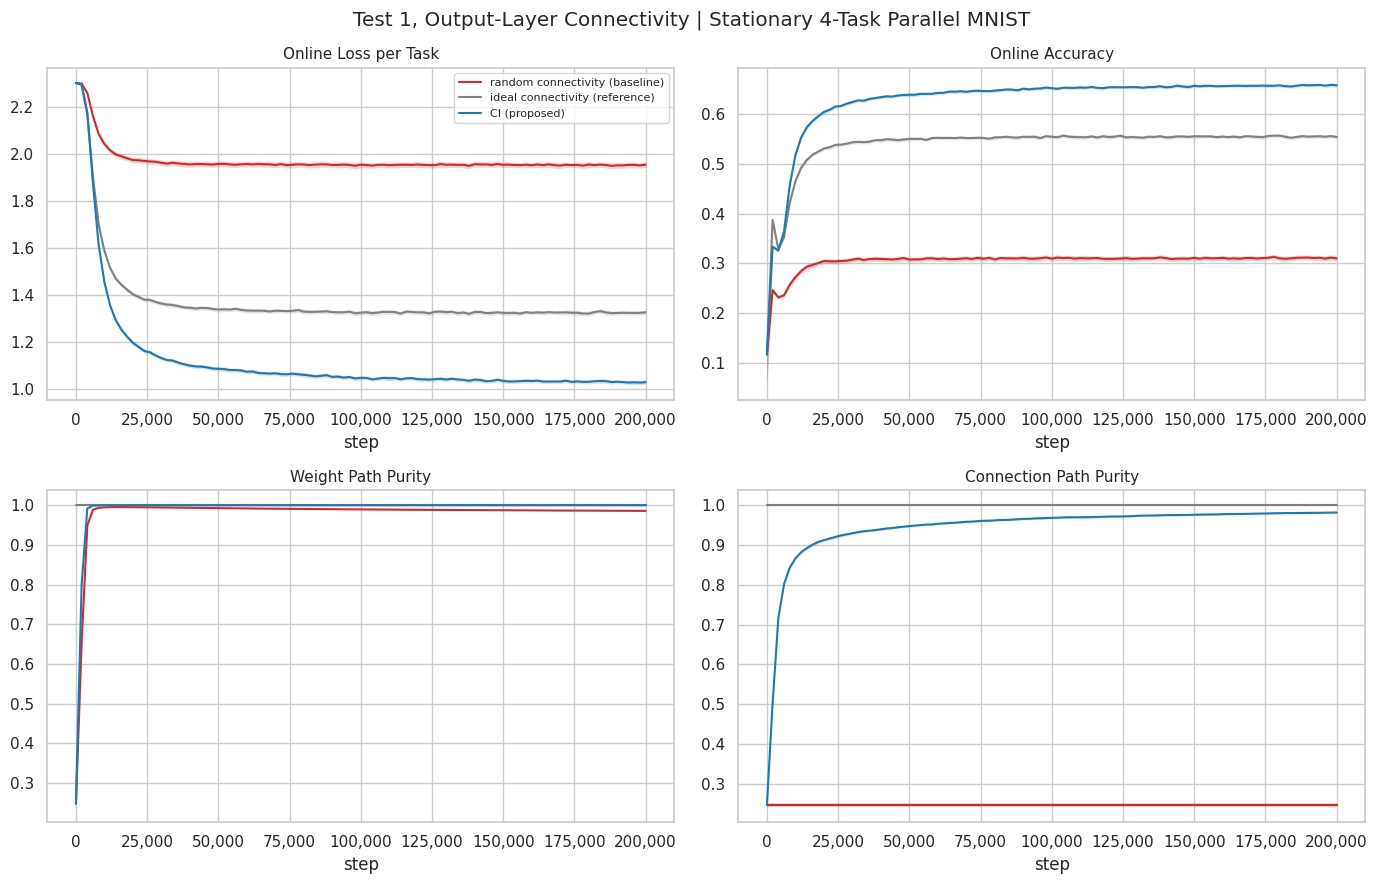

random connectivity (baseline)  loss 1.953   accuracy 0.311   weight purity 0.986   connection purity 0.247
ideal connectivity (reference)  loss 1.325   accuracy 0.555   weight purity 1.000   connection purity 1.000
CI (proposed)                   loss 1.030   accuracy 0.658   weight purity 1.000   connection purity 0.981
Share of the loss gap CI closes: 1.47


In [8]:
output_runs = test_runs(init_output_test, 'output')
plot_runs(output_runs, 'Test 1, Output-Layer Connectivity')
summarize(output_runs)

## Test 2: input layer

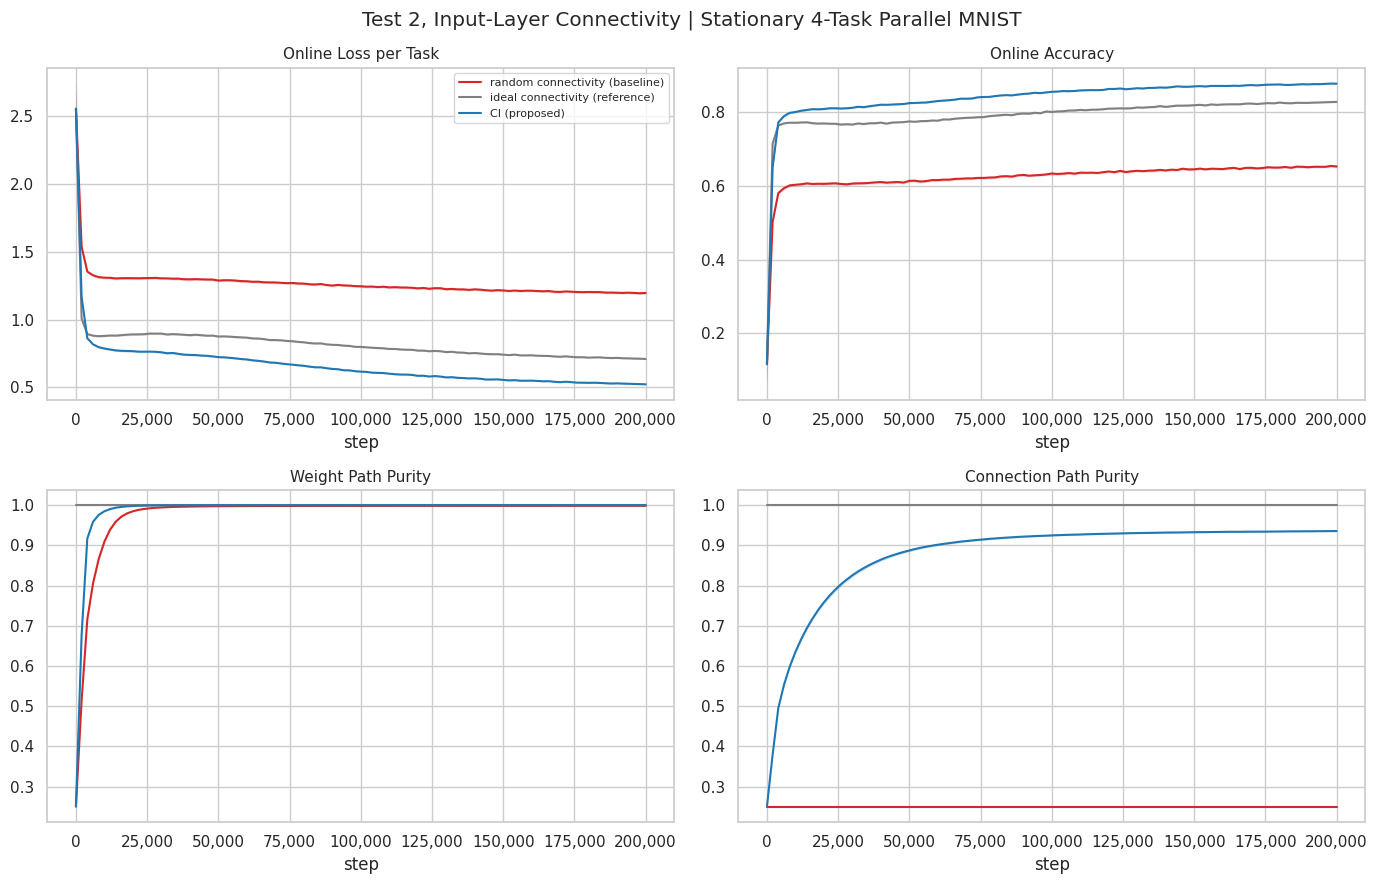

random connectivity (baseline)  loss 1.198   accuracy 0.652   weight purity 0.998   connection purity 0.250
ideal connectivity (reference)  loss 0.716   accuracy 0.826   weight purity 1.000   connection purity 1.000
CI (proposed)                   loss 0.529   accuracy 0.876   weight purity 1.000   connection purity 0.935
Share of the loss gap CI closes: 1.39


In [9]:
input_runs = test_runs(init_input_test, 'input')
plot_runs(input_runs, 'Test 2, Input-Layer Connectivity')
summarize(input_runs)

## Results

Over the last 10% of training, means over 30 seeds.

- **Test 1, output layer: H1 and H2 held.** CI's connection path purity is 0.981, against 0.247 with random
  connectivity. Its loss per task is 1.03, below both random connectivity (1.95) and ideal connectivity (1.33).
- **Test 2, input layer: H1 and H2 held.** CI's connection path purity is 0.935, against 0.250 with random
  connectivity. Its loss per task is 0.53, below both random connectivity (1.20) and ideal connectivity (0.72).
- **CI beats ideal connectivity in both tests**, likely because it chooses which of its task's sources each unit
  reads, while ideal connectivity reads a fixed random subset of them.
- **Weight path purity is near 1 even with random connectivity** (0.99 and 1.00), because Autostep keeps the weights
  of cross-task connections small. Connection path purity is the metric that shows whether connectivity was learned.